<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/27_QML_Privacy_Data_Leakage/QNN_EncodingLeakage_Upadhyay2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Encoding-scheme leakage of a QNN through its transpiled circuit: "Quantum Quandaries" (Upadhyay and Ghosh, 2025) step by step

This notebook re-implements, runs and checks the attack and the defence of

> Suryansh Upadhyay and Swaroop Ghosh (The Pennsylvania State University),
> "Quantum Quandaries: Unraveling Encoding Vulnerabilities in Quantum Neural Networks",
> arXiv:2502.01486 [quant-ph], 3 February 2025. https://arxiv.org/abs/2502.01486

The paper publishes no code and no data. Its "dataset" is a set of *quantum circuits that the authors generated themselves*, so everything
below is written from the paper's description with the software family it names (Qiskit, `GenericBackendV2`, scikit-learn). Nothing is downloaded and no quantum
hardware or cloud account is needed: all circuits are built and transpiled locally.

**The story in four sentences.** A company trains a quantum neural network (QNN) on a third-party quantum cloud. To run the job the cloud receives the
*transpiled* circuit, which starts with a data-loading ("encoding") block: basis, angle or amplitude encoding. The paper claims that each encoding leaves
a recognisable fingerprint in the gates the compiler produces (X and SX gates, RZ-SX sequences, angle statistics), so a curious cloud can tell *which
encoding* the user chose with about 95 % accuracy, a first step towards stealing the state-preparation circuit and the data inside it. The proposed defence inserts a
randomised "cloaking" layer (Hadamard, random RX rotations, CNOTs) behind the encoding and its exact inverse behind a barrier; it is meant to push the cloud's accuracy
down to about 42 % for about 8.5 % extra circuit depth.

**What the notebook does.**
1. Generates labelled circuits (amplitude, basis, angle-Rx, -Ry, -Rz encodings followed by a random parameterised circuit), transpiles them on a noisy fake backend, and extracts the paper's 27 + 2 x qubits features.
2. Explores that dataset (class counts, feature distributions, a 2-D projection coloured by true encoding) and draws the circuits that are actually executed.
3. Plays the *adversary*: a 25-10 multilayer perceptron (and two classical baselines) predicts the encoding from the features; Table I, Fig. 2 and a confusion matrix are redrawn.
4. Repeats the attack for 3 to 6 (FAST) or 3 to 8 (full) qubits (the paper's Fig. 3 goes to 14) and over the compiler's optimisation levels 0 to 3, which the paper does not specify but which turns out to matter.
5. Applies the paper's obfuscation defence, proves with state vectors that it does not change the circuit's output, and measures the attack accuracy and the depth overhead (Table II).
6. Prints the paper's numbers next to ours with a verdict for every claim, and reads the paper critically.

**How to run it.** Open in Colab (badge above), choose a CPU runtime and use *Runtime -> Run all*. The first cell installs pinned packages; if Colab asks to restart the
session, restart and run all again. `FAST_MODE = True` is a class demo (1 000 circuits for the main experiment, 3 to 6 qubits, about 10 minutes on a CPU);
`FAST_MODE = False` is the paper-sized run (22 500 circuits, 3 to 8 qubits, 5 seeds; see the configuration cell for its run time). The notebook saved in the
repository was executed with the setting written in its configuration cell; the other mode is one edit away.

**What you get at the end.** The paper's Table I, Fig. 2, Fig. 3 and Table II redrawn from our own runs, a table of paper numbers versus our numbers with a verdict per claim,
and a critical reading of what the experiment does and does not show.

## The paper in one page

**Problem.** Quantum-machine-learning-as-a-service: users send circuits to a remote quantum computer, often run by a third party. Training is expensive, so the trained model, its
state-preparation circuit and the data inside it are valuable. The paper asks whether the provider can learn *how the data were encoded* just by looking at the compiled circuit.

**Threat model.** The adversary is the cloud provider with white-box access to the transpiled circuit and the measurement results. The victim uses exactly one of three encodings with one
feature per qubit: angle (Pauli rotation Rx, Ry or Rz), amplitude or basis. The adversary wants the encoding type (and, for angle encoding, the rotation axis), as a first step towards extracting the data or cloning the model.

**Attack (paper Section III-C).**
1. *Data set.* Encoding layer: Rx/Ry/Rz(x_i) with x_i ~ U(0, 2 pi); amplitude encoding of a Haar-random 2^n-dimensional state vector; basis encoding with X gates. Followed by parameterised circuits (PQCs)
   with different "starting gates" from {rx, ry, rz, cx, x, sx, crx, cry, crz}. Transpiled with Qiskit on the noisy fake backend `GenericBackendV2`. Label = encoding type (5 classes: amplitude, basis, Rx, Ry, Rz).
   Example: 3 qubits, 18 000 circuits for training and validation (so 22 500 in total with the 4 500 test circuits of Table I).
2. *Features.* 27 + 2 x qubits numbers per circuit (33 for 3 qubits): structural signatures (X/SX ratios, binary pre-CNOT patterns, RZ-SX sequences), rotation analysis (mean, standard deviation,
   entropy of angles per gate type, correlation of consecutive angles, angles mod 2 pi) and entanglement signatures. The paper does not list them one by one.
3. *Classifier.* Stratified 60/20/20 split, z-score normalisation, multilayer perceptron with hidden layers of 25 and 10 ReLU neurons and a softmax output over the 5 encodings, Adam, at most 100 iterations.

**Defence (Section IV).** Right after the encoding: `H` and `RX(theta_i)` with `theta_i ~ U(-pi, pi)` on every qubit and CNOTs on the pairs (0,1), (2,3), ...; then a *barrier* that stops the compiler from optimising
across it; then the exact inverse (CNOTs, `RX(-theta_i)`, `H`); then the PQC. The state entering the PQC is unchanged, but the transpiled circuit looks different.

**Claims (numbers from the text, tables and figure descriptions).**

| # | Claim | Paper value |
|---|---|---|
| C1 | Attack accuracy for a 3-qubit QNN (Table I; text: "about 95 %") | accuracy 0.94 (macro and weighted F1 0.94) |
| C2 | Per-encoding precision / recall / F1 (Table I) | Amplitude 1.00/1.00/1.00; Basis 0.93/0.81/0.87; Rx 0.92/0.96/0.94; Ry 0.93/0.97/0.95; Rz 0.95/0.98/0.96 |
| C3 | Training dynamics (Fig. 2, text) | validation accuracy reaches 80 % at epoch 40; training accuracy about 90 % at epoch 100; training loss falls monotonically from 1.2 to 0.2 |
| C4 | Feature count is `27 + 2 x qubits` (Eq. 1) | 33 at 3 qubits, 55 at 14 qubits, 227 at 100 qubits |
| C5 | Accuracy against qubit count (Fig. 3, text) | 94 % at 3 qubits; improving from 90 % to 95 % up to 14 qubits |
| C6 | Defence efficacy (Fig. 3, text) | attack accuracy falls from about 95 % to an average of 42 % over the encodings |
| C7 | Depth overhead of the defence, 5-layer low-depth PQC, 800 circuits per encoding (Table II) | about 8.5 % on average; Amplitude 95.2 -> 101.1 (+6.2 %), Basis 67.6 -> 74.1 (+9.7 %), Rx 70.2 -> 76.1 (+8.4 %), Ry 69.2 -> 76.1 (+10 %), Rz 67.7 -> 74.1 (+9.5 %) |
| C8 | The defence preserves the circuit's function | qualitative (the PQC "operates directly on the originally encoded state") |

### What follows the paper and what had to be chosen

The paper is a short workshop-style paper and many settings are not stated. Every choice below is marked `# CHOICE:` in the code.

| Item | Paper | This notebook |
|---|---|---|
| Circuits per class / total | 3 qubits, 18 000 train+validation circuits, 4 500 test circuits (900 per class, Table I) | full run: 4 500 circuits per encoding = 22 500; FAST: 200 per encoding |
| Encoding layer | Rj(x_i), x_i ~ U(0, 2 pi); Haar-random amplitudes; X gates for basis | same; amplitude: complex Gaussian vector, normalised (= Haar-random state), loaded with `prepare_state` (**not** `initialize`, which would add `reset` instructions that give the encoding away); basis: independent random bits |
| PQC | "PQCs with different starting gates P = {rx, ry, rz, cx, x, sx, crx, cry, crz}", entanglement patterns and gate types vary | **a layer is a starting block (first layer: the starting gate; later layers: a random gate of P), a rotation block with a random axis, and a CNOT chain**; 1 to 5 layers drawn per circuit; all angles ~ U(0, 2 pi) |
| Measurement | not stated | `measure_all()` at the end |
| Backend and transpiler | Qiskit `GenericBackendV2` ("noisy fake back-end") | `GenericBackendV2(num_qubits=n)` with a **line** coupling map, basis {cx, id, rz, sx, x}, seed 42 |
| **Transpiler optimisation level** | **not stated** | **`OPT_LEVEL` below; Section 4 repeats the experiment for levels 0 to 3**, because the compiler's own optimisation decides how much of the encoding survives |
| The 27 global features | only the three families are described | **our own list of 27** (Section 1; two of the families, "structural" and "rotation", follow the paper's wording; the "front" features read the first gates on every qubit); plus 2 per qubit (number of single-qubit gates, mean RZ angle) |
| Split and scaling | stratified 60/20/20, z-score | same; z-score fitted on the training part only |
| Classifier | MLP 25-10, ReLU, Adam, 100 iterations, softmax over 5 classes | `sklearn.neural_network.MLPClassifier((25, 10))`, trained epoch by epoch with `partial_fit` for 100 epochs, default batch size 200 and learning rate 1e-3 |
| Baselines | none | RandomForest (200 trees) and SVC (rbf) on the identical z-scored features; a majority-class rule (chance = 20 %) |
| Qubit sweep (Fig. 3) | 3 to 14 qubits | 3 to 6 (FAST) / 3 to 8 (full): amplitude encoding of n qubits compiles to about 4^n gates, so 14 qubits is far beyond a CPU session |
| Defence evaluation | "a test dataset incorporating the defence", classifier from the undefended data | **the same test circuits rebuilt with the defence** (same encoding, same PQC), classified by the undefended classifier; additionally an *adaptive* adversary retrained on defended circuits (not in the paper) |
| Depth table | 800 instances per encoding, 5-layer PQC | same in the full run (FAST: 60); mean `QuantumCircuit.depth()` of the transpiled circuits, original versus defended |
| Seeds | not stated | `SEED = 42`; 5 seeds (2 in FAST) for the split and the network initialisation; the circuits are generated once |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn, scipy and matplotlib.
# The pip line runs on Colab (or wherever qiskit is missing); a prepared local environment is left untouched.
import importlib.util, sys
IN_COLAB = importlib.util.find_spec("google.colab") is not None
_missing = [m for m in ("qiskit", "qiskit_aer", "pylatexenc") if importlib.util.find_spec(m) is None]
if IN_COLAB or _missing:
    %pip install -q "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("qiskit / pylatexenc already present; skipping pip install.")

qiskit / pylatexenc already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False       # True: class demo (about 10 minutes on a CPU). False: paper-sized run (see the sizes below).
SEED      = 42         # CHOICE: the paper gives no seed
IBM_TOKEN = ""         # not needed: everything is simulated locally (kept for convention; no real-hardware cell here)
DATA_DIR  = "qc214_data"   # cache of the generated feature tables (relative to the working directory)

N_QUBITS  = 3          # paper: 3-qubit QNN for Table I and Fig. 2
OPT_LEVEL = 2          # CHOICE: transpiler optimisation level for the main experiment (the paper does not say); Section 4 sweeps 0..3
EPOCHS    = 100        # paper: at most 100 training iterations
HIDDEN    = (25, 10)   # paper: hidden layers of 25 and 10 neurons

if FAST_MODE:
    PER_CLASS        = 200            # circuits per encoding for the main experiment (paper: 4 500)
    SEEDS            = [42, 43]       # split / initialisation seeds (full: 5)
    SWEEP_QUBITS     = [3, 4, 5, 6]   # Fig. 3 (paper: 3..14)
    PER_CLASS_SWEEP  = 100            # circuits per encoding and qubit count in the sweep
    PER_CLASS_DEPTH  = 60             # Table II (paper: 800)
    OPT_SWEEP        = [0, 1, 2, 3]   # compiler optimisation levels (extra experiment)
    PER_CLASS_OPT    = 80
    ADAPT_PER_CLASS  = 60             # adaptive adversary: defended training circuits per encoding
else:
    PER_CLASS        = 4500           # 22 500 circuits in total, 4 500 test circuits (900 per class) as in Table I
    SEEDS            = [42, 43, 44, 45, 46]
    SWEEP_QUBITS     = [3, 4, 5, 6, 7, 8]
    PER_CLASS_SWEEP  = 600
    PER_CLASS_DEPTH  = 800
    OPT_SWEEP        = [0, 1, 2, 3]
    PER_CLASS_OPT    = 500
    ADAPT_PER_CLASS  = 500

In [3]:
import os, time, json, hashlib, warnings, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message=".*Maximum iterations.*")

import qiskit, sklearn, scipy
from qiskit import QuantumCircuit, transpile
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import CouplingMap
from qiskit.quantum_info import Statevector, Operator
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 80)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
rng = np.random.default_rng(SEED)              # every circuit also carries its own seed (see make_specs), so the data do not depend on call order
np.random.seed(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
print("qiskit", qiskit.__version__, "| scikit-learn", sklearn.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)

qiskit 2.5.2 | scikit-learn 1.9.1 | numpy 2.5.4 | scipy 1.18.1


## 1. The attack's data: encoding circuits, transpiled, turned into features

**Generating circuits.** A circuit is `encoding -> PQC -> measurement` (the victim's QNN as in the paper's Fig. 1). Instead of storing circuit objects we store a tiny *specification*
(encoding type, qubits, PQC layers, starting gate, a per-circuit seed) and rebuild the circuit from it whenever needed. That makes the data reproducible
and lets us rebuild *the same circuit with the defence* later by flipping one flag.

**What the cloud sees.** The circuit is transpiled to the basis gates of the (fake) device, `cx`, `rz`, `sx`, `x`, and mapped to its qubit line. Rotations such as `Rx(x)` become sequences like `Rz . SX . Rz . SX . Rz`; an amplitude-encoding block
becomes dozens of `Rz`, `SX` and `CX` gates; a basis-encoding block stays a few `X` gates. Those are the "transpilation artefacts" of the paper.

In [4]:
# ---- circuit generation (everything marked CHOICE is not specified by the paper) ----
ENCODINGS = ["amplitude", "basis", "rx", "ry", "rz"]          # the paper's five classes (Table I): amplitude, basis, angle-Rx/Ry/Rz
ENC_LABEL = {"amplitude": "Amplitude", "basis": "Basis", "rx": "Angle Rx", "ry": "Angle Ry", "rz": "Angle Rz"}
START_GATES = ["rx", "ry", "rz", "cx", "x", "sx", "crx", "cry", "crz"]   # paper: the set P of PQC starting gates

def spec_rng(spec, salt=0):
    """Every circuit is rebuilt deterministically from its spec (kind, n, layers, start gate, seed): no circuit objects are stored."""
    return np.random.default_rng([spec["seed"], salt])

def encoding_circuit(n, kind, rng):
    qc = QuantumCircuit(n, name=f"enc_{kind}")
    if kind in ("rx", "ry", "rz"):                       # Pauli rotations R_j(x_i), x_i ~ U(0, 2 pi), one feature per qubit
        for q in range(n):
            getattr(qc, kind)(float(rng.uniform(0, 2 * np.pi)), q)
    elif kind == "amplitude":                            # Haar-random complex state vector on n qubits (2^n amplitudes)
        v = rng.normal(size=2 ** n) + 1j * rng.normal(size=2 ** n)
        qc.prepare_state(v / np.linalg.norm(v), range(n))   # CHOICE: StatePreparation (no reset gates), not initialize()
    elif kind == "basis":                                # bit i of a random binary string -> X on qubit i
        for q, b in enumerate(rng.integers(0, 2, n)):
            if b:
                qc.x(q)
    else:
        raise ValueError(kind)
    return qc

def pqc_block(qc, n, kind, rng):
    """One block of the PQC built from the gate named `kind` (random angles for the parametrised gates)."""
    if kind in ("rx", "ry", "rz"):
        for q in range(n):
            getattr(qc, kind)(float(rng.uniform(0, 2 * np.pi)), q)
    elif kind in ("x", "sx"):
        for q in range(n):
            getattr(qc, kind)(q)
    elif kind == "cx":
        for q in range(n - 1):
            qc.cx(q, q + 1)
    elif kind in ("crx", "cry", "crz"):
        for q in range(n - 1):
            getattr(qc, kind)(float(rng.uniform(0, 2 * np.pi)), q, q + 1)

def pqc_circuit(n, layers, start, rng):
    """CHOICE: layer = [starting block] + [rotation layer, random axis] + [CNOT chain]. The first layer starts with `start`, later layers with a random gate of P."""
    qc = QuantumCircuit(n, name="pqc")
    for l in range(layers):
        pqc_block(qc, n, start if l == 0 else str(rng.choice(START_GATES)), rng)
        pqc_block(qc, n, str(rng.choice(["rx", "ry", "rz"])), rng)
        pqc_block(qc, n, "cx", rng)
    return qc

def obfuscation_layers(n, rng):
    """Paper Section IV: H, RX(theta_i) with theta_i ~ U(-pi, pi) on every qubit, CNOT(0,1), CNOT(2,3), ... ; the inverse is applied after a barrier."""
    thetas = rng.uniform(-np.pi, np.pi, n)
    obf = QuantumCircuit(n, name="obf")
    for q in range(n):
        obf.h(q); obf.rx(float(thetas[q]), q)
    for j in range(0, n - 1, 2):
        obf.cx(j, j + 1)
    return obf, obf.inverse()                             # inverse = CNOTs in reverse order, RX(-theta), H

def build_qnn(spec, defended=False, measure=True):
    """Encoding -> [obfuscation | barrier | inversion] -> PQC -> measurement.  Same spec + same seed = same encoding and PQC with or without defence."""
    n = spec["n"]
    enc = encoding_circuit(n, spec["enc"], spec_rng(spec, 0))
    pqc = pqc_circuit(n, spec["layers"], spec["start"], spec_rng(spec, 1))
    qc = QuantumCircuit(n, name=f"qnn_{spec['enc']}")
    qc.compose(enc, inplace=True)
    if defended:
        obf, inv = obfuscation_layers(n, spec_rng(spec, 2))
        qc.compose(obf, inplace=True); qc.barrier(); qc.compose(inv, inplace=True)
    qc.compose(pqc, inplace=True)
    if measure:
        qc.measure_all()
    return qc

def make_specs(n, per_class, seed, layers=None):
    """per_class circuits for each encoding; PQC depth random in 1..5 layers (or fixed), start gate random from P."""
    r = np.random.default_rng(seed)
    specs = []
    for kind in ENCODINGS:
        for _ in range(per_class):
            specs.append(dict(enc=kind, n=n, layers=int(layers if layers else r.integers(1, 6)),
                              start=str(r.choice(START_GATES)), seed=int(r.integers(0, 2 ** 31 - 1))))
    return specs

_BACKENDS = {}
def get_backend(n):
    if n not in _BACKENDS:   # CHOICE: GenericBackendV2 (noisy fake device) with a line coupling map, basis {cx, id, rz, sx, x}
        _BACKENDS[n] = GenericBackendV2(num_qubits=n, coupling_map=CouplingMap.from_line(n, bidirectional=True), seed=SEED)
    return _BACKENDS[n]

def transpile_specs(specs, defended=False, opt=None, chunk=400):
    """Build and transpile circuits in chunks (Qiskit parallelises a list over processes); returns the transpiled circuits."""
    out = []
    for i in range(0, len(specs), chunk):
        qcs = [build_qnn(s, defended) for s in specs[i:i + chunk]]
        out += transpile(qcs, get_backend(specs[0]["n"]), optimization_level=OPT_LEVEL if opt is None else opt, seed_transpiler=SEED)
    return out

**Features (27 + 2 x qubits, paper Eq. 1).** The paper describes three families but does not list its 27 global features. Our list is below. They are computed from the **transpiled** circuit only,
never from the specification, because that is all the cloud sees.

* *Structural signatures*: depth, number of gates, counts of `rz`, `sx`, `x`, `cx`, shares of `x`, `sx`, `rz`, `cx`, the X/SX ratio (basis encoding), numbers of `RZ-SX` pairs and `SX-RZ-SX` triples (typical compiler output for a rotation), `X` gates directly before a `CX` (a binary pre-CNOT pattern).
* *Rotation analysis*: mean, standard deviation and entropy of the `rz` angles (theta mod 2 pi), correlation of consecutive angles, share of angles that are multiples of pi/2 (a rotation about a fixed Clifford angle looks different from a random data angle).
* *Entanglement signature*: number of distinct qubit pairs coupled by a `cx`.
* *"Front" features* (our addition inside the 27): what the *first* gates on each qubit are (`x`, `rz`, `sx`, `rz`-then-`sx`, `sx`-then-`rz`, and whether the first `rz` has a fixed pi/2-multiple angle). The data-loading block is the first thing to happen on a qubit, so this is where the encoding sits.
* *Per qubit (2 each)*: number of single-qubit gates on the qubit and the mean `rz` angle on the qubit.

In [5]:
# ---- feature extraction from a transpiled circuit ----
GLOBAL_FEATURES = [
    "depth", "size", "n_rz", "n_sx", "n_x", "n_cx",                                         # structure: depth and gate counts
    "frac_x", "frac_sx", "frac_rz", "frac_cx", "ratio_x_over_sx",                           # basis-encoding markers: share of X / SX gates
    "n_rz_sx_pairs", "n_sx_rz_sx_triples", "n_x_before_cx",                                 # transpilation artefacts: RZ-SX sequences, binary pre-CNOT patterns
    "rz_mean", "rz_std", "rz_entropy", "rz_unique_frac", "rz_consec_corr", "rz_frac_halfpi_multiples",        # rotation analysis: statistics of the RZ angles (theta mod 2 pi)
    "n_cx_pairs_distinct",                                                                  # entanglement signature
    "front_first_x", "front_first_rz", "front_first_sx", "front_rz_sx", "front_sx_rz", "front_first_rz_halfpi",   # "front" of each qubit = its first gates, where the encoding sits
]
assert len(GLOBAL_FEATURES) == 27                                                            # paper: Features = 27 + 2 x qubits (Eq. 1)
FRONT_FEATURES = [f for f in GLOBAL_FEATURES if f.startswith("front_")]

def feature_names(n):
    return GLOBAL_FEATURES + [f"q{q}_n1q" for q in range(n)] + [f"q{q}_rz_mean" for q in range(n)]

def _halfpi(a):
    return bool(np.isclose(a % (np.pi / 2), 0, atol=1e-6) or np.isclose(a % (np.pi / 2), np.pi / 2, atol=1e-6))

def circuit_features(tqc):
    """27 global + 2 per-qubit features (Eq. 1) read from a TRANSPILED circuit, i.e. exactly what a cloud provider sees."""
    n = tqc.num_qubits
    ops = []                                                       # (name, qubits, angle) in program order; barriers and measurements dropped
    for inst in tqc.data:
        nm = inst.operation.name
        if nm in ("barrier", "measure", "delay"):
            continue
        qs = tuple(tqc.find_bit(q).index for q in inst.qubits)
        ang = float(inst.operation.params[0]) % (2 * np.pi) if nm == "rz" else np.nan
        ops.append((nm, qs, ang))
    cnt = lambda nm: sum(1 for o in ops if o[0] == nm)
    n_rz, n_sx, n_x, n_cx = cnt("rz"), cnt("sx"), cnt("x"), cnt("cx")
    size = len(ops)
    tl = {q: [] for q in range(n)}                                 # per-qubit timeline of gate names
    first_rz_angle = {}                                            # angle of the first RZ on a qubit (if it is also the first gate)
    for nm, qs, ang in ops:
        for q in qs:
            if not tl[q] and nm == "rz":
                first_rz_angle[q] = ang
            tl[q].append(nm)
    # "front" features: what is the first thing that happens on each qubit (the state-preparation front)
    fq = [q for q in range(n) if tl[q]]
    nf = max(len(fq), 1)
    first = [tl[q][0] for q in fq]; first2 = [tuple(tl[q][:2]) for q in fq]
    f_x, f_rz, f_sx = first.count("x") / nf, first.count("rz") / nf, first.count("sx") / nf
    f_rzsx, f_sxrz = first2.count(("rz", "sx")) / nf, first2.count(("sx", "rz")) / nf
    f_halfpi = float(np.mean([_halfpi(a) for a in first_rz_angle.values()])) if first_rz_angle else 0.0
    rz_sx = sum(1 for q in tl for a, b in zip(tl[q], tl[q][1:]) if a == "rz" and b == "sx")
    sx_rz_sx = sum(1 for q in tl for a, b, c in zip(tl[q], tl[q][1:], tl[q][2:]) if (a, b, c) == ("sx", "rz", "sx"))
    last = {q: None for q in range(n)}; x_before_cx = 0           # X gate immediately before a CNOT = binary pre-CNOT pattern
    for nm, qs, ang in ops:
        if nm == "cx":
            x_before_cx += sum(1 for q in qs if last[q] == "x")
        for q in qs:
            last[q] = nm
    angs = np.array([o[2] for o in ops if o[0] == "rz"])
    if len(angs):
        hist = np.histogram(angs, bins=12, range=(0, 2 * np.pi))[0] / len(angs)
        ent = float(-(hist[hist > 0] * np.log(hist[hist > 0])).sum())
        ok = len(angs) >= 3 and angs[:-1].std() > 1e-9 and angs[1:].std() > 1e-9
        corr = float(np.corrcoef(angs[:-1], angs[1:])[0, 1]) if ok else 0.0
        halfpi = float(np.mean([_halfpi(a) for a in angs]))
        uniq = len(np.unique(np.round(angs, 3))) / len(angs)         # diversity of rotation parameters (high for random data angles)
        mean, std = float(angs.mean()), float(angs.std())
    else:
        ent = corr = halfpi = mean = std = uniq = 0.0
    cx_pairs = {tuple(sorted(o[1])) for o in ops if o[0] == "cx"}
    g = [tqc.depth(), size, n_rz, n_sx, n_x, n_cx,
         n_x / max(size, 1), n_sx / max(size, 1), n_rz / max(size, 1), n_cx / max(size, 1), n_x / (n_sx + 1),
         rz_sx, sx_rz_sx, x_before_cx,
         mean, std, ent, uniq, corr, halfpi,
         len(cx_pairs),
         f_x, f_rz, f_sx, f_rzsx, f_sxrz, f_halfpi]
    per_q_n1q = [sum(1 for o in ops if len(o[1]) == 1 and o[1][0] == q) for q in range(n)]
    per_q_rz = [float(np.mean([o[2] for o in ops if o[0] == "rz" and o[1][0] == q] or [0.0])) for q in range(n)]
    return np.array(g + per_q_n1q + per_q_rz, dtype=float)

def featurise(tqcs):
    return np.vstack([circuit_features(t) for t in tqcs])

In [6]:
def build_features(specs, defended=False, opt=None, tag=""):
    """specs -> (transpile on the fake backend) -> feature matrix. Cached in DATA_DIR by a hash of the specs."""
    opt = OPT_LEVEL if opt is None else opt
    key = hashlib.md5(json.dumps([specs, defended, opt, SEED, qiskit.__version__], sort_keys=True).encode()).hexdigest()[:12]
    path = os.path.join(DATA_DIR, f"feat_{tag}_{key}.npy")
    if os.path.exists(path):
        return np.load(path)
    X = featurise(transpile_specs(specs, defended=defended, opt=opt))
    np.save(path, X)
    return X

# ---- main data set: 3 qubits, PER_CLASS circuits per encoding ----
t0 = time.time()
SPECS = make_specs(N_QUBITS, PER_CLASS, SEED)
X_ALL = build_features(SPECS, tag="main")
Y_ALL = np.array([ENCODINGS.index(s["enc"]) for s in SPECS])
NAMES = feature_names(N_QUBITS)
T_GEN = time.time() - t0
assert X_ALL.shape == (5 * PER_CLASS, 27 + 2 * N_QUBITS) and len(NAMES) == X_ALL.shape[1]
print(f"{len(SPECS)} circuits generated, transpiled (optimisation level {OPT_LEVEL}) and turned into {X_ALL.shape[1]} features each in {T_GEN:.0f} s")

22500 circuits generated, transpiled (optimisation level 2) and turned into 33 features each in 511 s


## Dataset Exploration and Visualisation

The "data" here are circuits, so a data point is one transpiled circuit described by its 33 numbers and labelled by the encoding the user chose (the true label, which the adversary does not know). The cells below
print the table's shape, the feature names and the label counts, plot the real class distribution, show how single features differ between encodings, and draw a 2-D projection of the real circuits coloured by their ground-truth label.

In [7]:
# train / validation / test split (stratified 60/20/20, as in the paper); this is the split of the main seed
def split_idx(y, seed):
    idx = np.arange(len(y))
    itv, ite = train_test_split(idx, test_size=0.2, stratify=y, random_state=seed)
    itr, iva = train_test_split(itv, test_size=0.25, stratify=y[itv], random_state=seed)
    return itr, iva, ite

ITR, IVA, ITE = split_idx(Y_ALL, SEED)
print("feature table shape (circuits x features):", X_ALL.shape, "| train / validation / test:", len(ITR), len(IVA), len(ITE))
print("number of features = 27 + 2 x qubits =", 27 + 2 * N_QUBITS)
print("\nfeature names:", NAMES)
print("\noriginal labels (encoding schemes) and counts, whole set / train / validation / test:")
counts = pd.DataFrame({"label": [ENC_LABEL[e] for e in ENCODINGS],
                       "all": np.bincount(Y_ALL, minlength=5), "train": np.bincount(Y_ALL[ITR], minlength=5),
                       "validation": np.bincount(Y_ALL[IVA], minlength=5), "test": np.bincount(Y_ALL[ITE], minlength=5)})
display(counts)
print("\nfirst rows of the feature table (rows = circuits of different encodings):")
ex_idx = [int(np.where(Y_ALL == c)[0][0]) for c in range(5)]
display(pd.DataFrame(X_ALL[ex_idx], columns=NAMES, index=[ENC_LABEL[ENCODINGS[Y_ALL[i]]] for i in ex_idx]).round(2).T)

feature table shape (circuits x features): (22500, 33) | train / validation / test: 13500 4500 4500
number of features = 27 + 2 x qubits = 33

feature names: ['depth', 'size', 'n_rz', 'n_sx', 'n_x', 'n_cx', 'frac_x', 'frac_sx', 'frac_rz', 'frac_cx', 'ratio_x_over_sx', 'n_rz_sx_pairs', 'n_sx_rz_sx_triples', 'n_x_before_cx', 'rz_mean', 'rz_std', 'rz_entropy', 'rz_unique_frac', 'rz_consec_corr', 'rz_frac_halfpi_multiples', 'n_cx_pairs_distinct', 'front_first_x', 'front_first_rz', 'front_first_sx', 'front_rz_sx', 'front_sx_rz', 'front_first_rz_halfpi', 'q0_n1q', 'q1_n1q', 'q2_n1q', 'q0_rz_mean', 'q1_rz_mean', 'q2_rz_mean']

original labels (encoding schemes) and counts, whole set / train / validation / test:


,label,all,train,validation,test
0,Amplitude,4500,2700,900,900
1,Basis,4500,2700,900,900
2,Angle Rx,4500,2700,900,900
3,Angle Ry,4500,2700,900,900
4,Angle Rz,4500,2700,900,900



first rows of the feature table (rows = circuits of different encodings):


,Amplitude,Basis,Angle Rx,Angle Ry,Angle Rz
depth,47.00,8.00,53.00,60.00,32.00
size,71.00,17.00,100.00,87.00,55.00
n_rz,35.00,9.00,46.00,39.00,25.00
n_sx,25.00,6.00,33.00,30.00,20.00
n_x,1.00,0.00,3.00,0.00,0.00
n_cx,10.00,2.00,18.00,18.00,10.00
frac_x,0.01,0.00,0.03,0.00,0.00
frac_sx,0.35,0.35,0.33,0.34,0.36
frac_rz,0.49,0.53,0.46,0.45,0.45
frac_cx,0.14,0.12,0.18,0.21,0.18


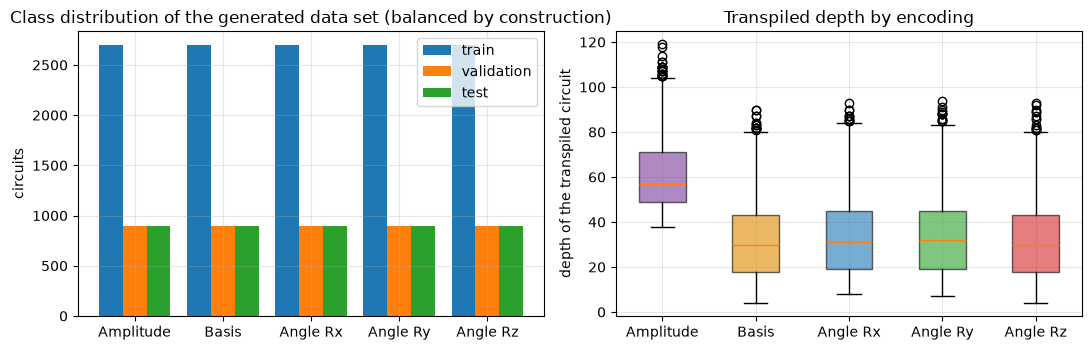

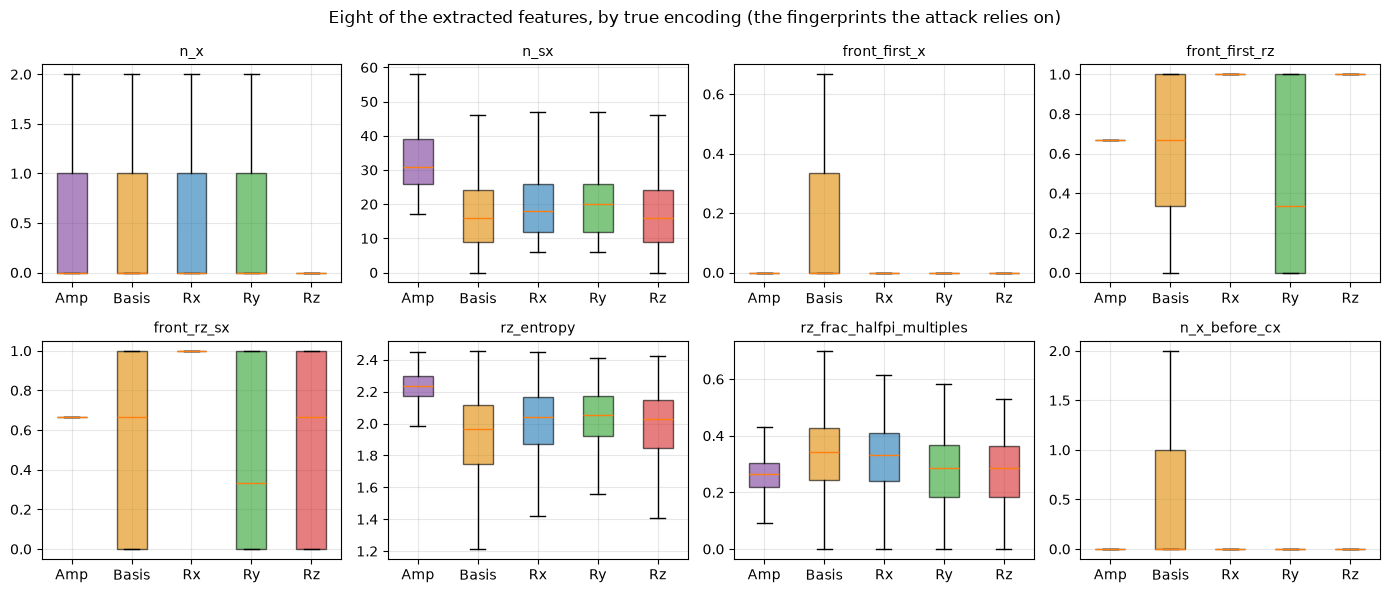

In [8]:
COLORS = {"amplitude": "#7a3b99", "basis": "#e08a00", "rx": "#1f77b4", "ry": "#2ca02c", "rz": "#d62728"}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
w = 0.2
for k, (part, idx) in enumerate([("train", ITR), ("validation", IVA), ("test", ITE)]):
    axes[0].bar(np.arange(5) + (k - 1) * 0.27, np.bincount(Y_ALL[idx], minlength=5), width=0.27, label=part)
axes[0].set_xticks(range(5)); axes[0].set_xticklabels([ENC_LABEL[e] for e in ENCODINGS]); axes[0].set_ylabel("circuits")
axes[0].set_title("Class distribution of the generated data set (balanced by construction)"); axes[0].legend()
depth_by = [X_ALL[Y_ALL == c, NAMES.index("depth")] for c in range(5)]
bp = axes[1].boxplot(depth_by, patch_artist=True); axes[1].set_xticks(range(1, 6)); axes[1].set_xticklabels([ENC_LABEL[e] for e in ENCODINGS])
for patch, e in zip(bp["boxes"], ENCODINGS): patch.set_facecolor(COLORS[e]); patch.set_alpha(0.6)
axes[1].set_ylabel("depth of the transpiled circuit"); axes[1].set_title("Transpiled depth by encoding")
plt.tight_layout(); plt.show()

show = ["n_x", "n_sx", "front_first_x", "front_first_rz", "front_rz_sx", "rz_entropy", "rz_frac_halfpi_multiples", "n_x_before_cx"]
fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, f in zip(axes.ravel(), show):
    j = NAMES.index(f)
    bp = ax.boxplot([X_ALL[Y_ALL == c, j] for c in range(5)], patch_artist=True, showfliers=False); ax.set_xticks(range(1, 6)); ax.set_xticklabels(["Amp", "Basis", "Rx", "Ry", "Rz"])
    for patch, e in zip(bp["boxes"], ENCODINGS): patch.set_facecolor(COLORS[e]); patch.set_alpha(0.6)
    ax.set_title(f, fontsize=10)
plt.suptitle("Eight of the extracted features, by true encoding (the fingerprints the attack relies on)"); plt.tight_layout(); plt.show()

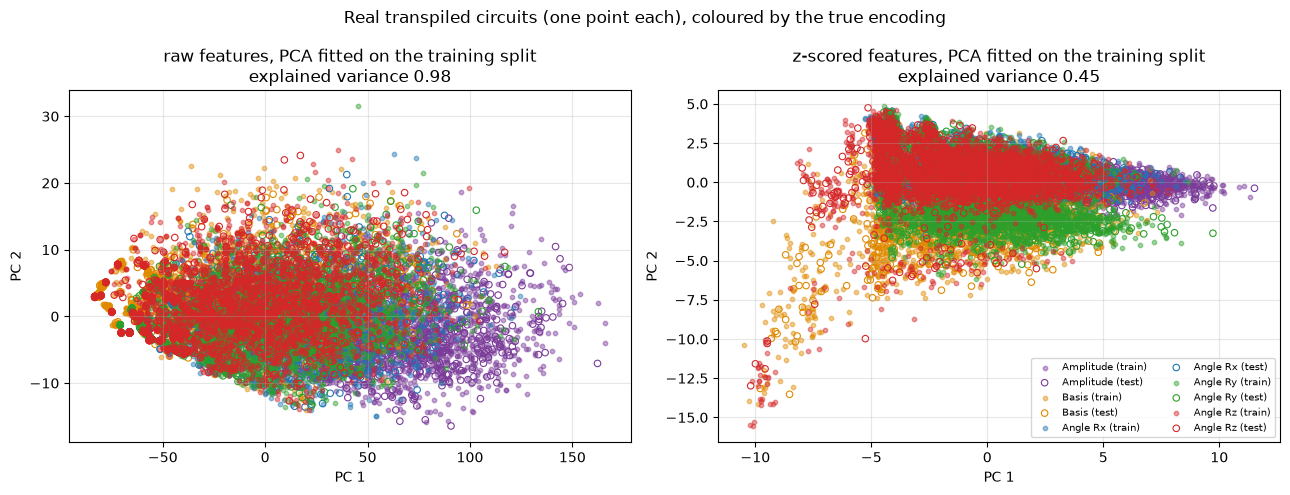

In [9]:
# 2-D scatter of the real circuits, coloured by ground-truth encoding.
# (a) raw PCA: PCA fitted on the training part of the raw feature table; (b) PCA of the z-scored features (what the classifier sees), also fitted on the training part only.
# There is no [0, pi] angle scaling here: the attacker's input is a classical feature vector, not rotation angles.
pca_raw = PCA(n_components=2, random_state=SEED).fit(X_ALL[ITR])
sc_vis = StandardScaler().fit(X_ALL[ITR])
pca_z = PCA(n_components=2, random_state=SEED).fit(sc_vis.transform(X_ALL[ITR]))
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (title, tf, pc) in zip(axes, [("raw features, PCA fitted on the training split", lambda A: A, pca_raw),
                                      ("z-scored features, PCA fitted on the training split", sc_vis.transform, pca_z)]):
    Ptr, Pte = pc.transform(tf(X_ALL[ITR])), pc.transform(tf(X_ALL[ITE]))
    for c, e in enumerate(ENCODINGS):
        m1, m2 = Y_ALL[ITR] == c, Y_ALL[ITE] == c
        ax.scatter(Ptr[m1, 0], Ptr[m1, 1], s=10, alpha=0.45, color=COLORS[e], label=f"{ENC_LABEL[e]} (train)")
        ax.scatter(Pte[m2, 0], Pte[m2, 1], s=22, facecolors="none", edgecolors=COLORS[e], linewidths=0.8, label=f"{ENC_LABEL[e]} (test)")
    ax.set_title(title + f"\nexplained variance {pc.explained_variance_ratio_.sum():.2f}"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
axes[1].legend(fontsize=7, ncol=2, loc="best")
plt.suptitle("Real transpiled circuits (one point each), coloured by the true encoding"); plt.tight_layout(); plt.show()

## Quantum Circuit Architecture

There are five encodings and one defence, but only a few *distinct* architectures: the victim QNN with an angle-encoding block (Rx, Ry and Rz differ only in the gate name), with a basis block, with an amplitude block,
the same QNN with the defence inserted, and (last) what the cloud actually receives after transpilation. Each figure below is the circuit that the rest of the notebook builds (`build_qnn`), for 3 qubits, a 2-layer PQC that starts with `cx`, and the same seed.
Gate parameters are fixed random numbers here: the encoding angles are *data*, the PQC angles are what a victim would train (counted below as trainable parameters).

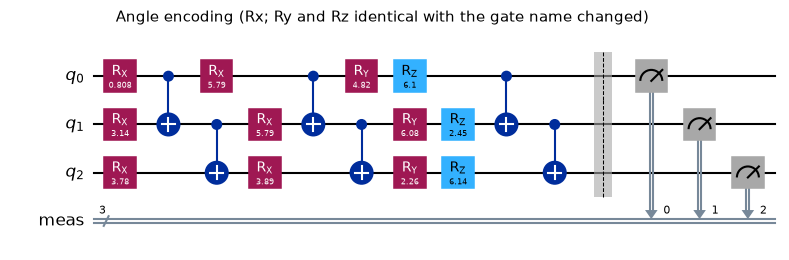

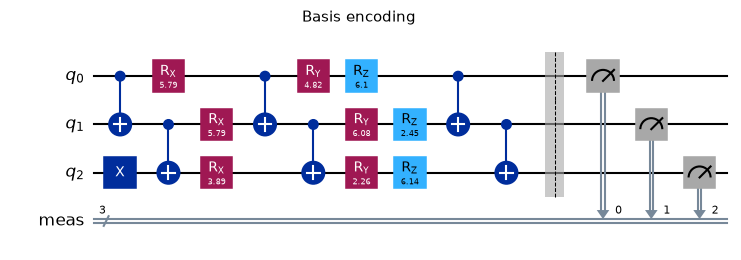

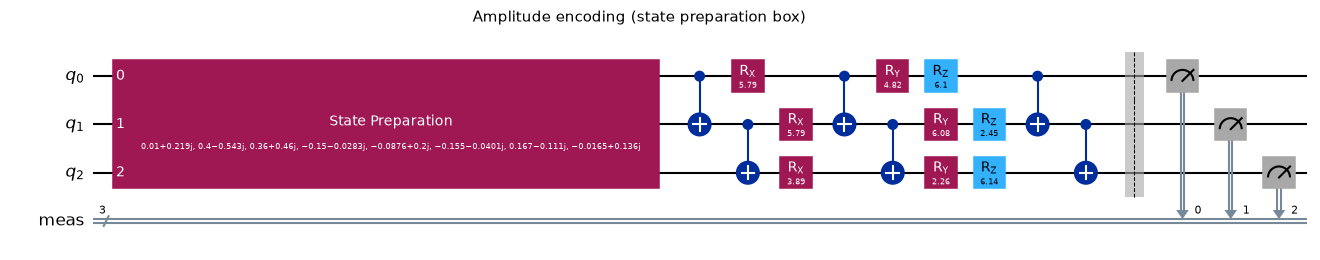

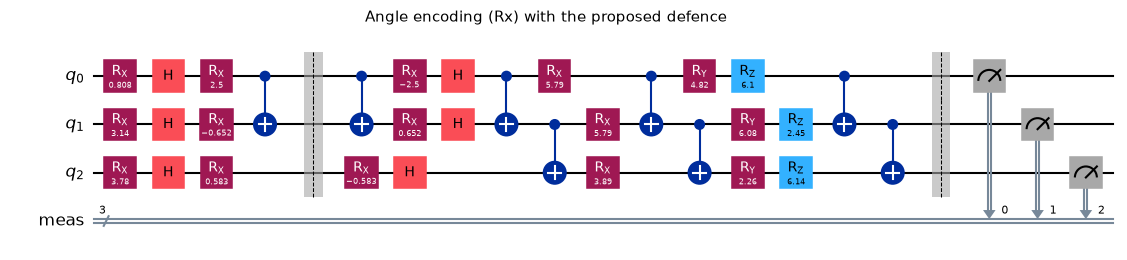

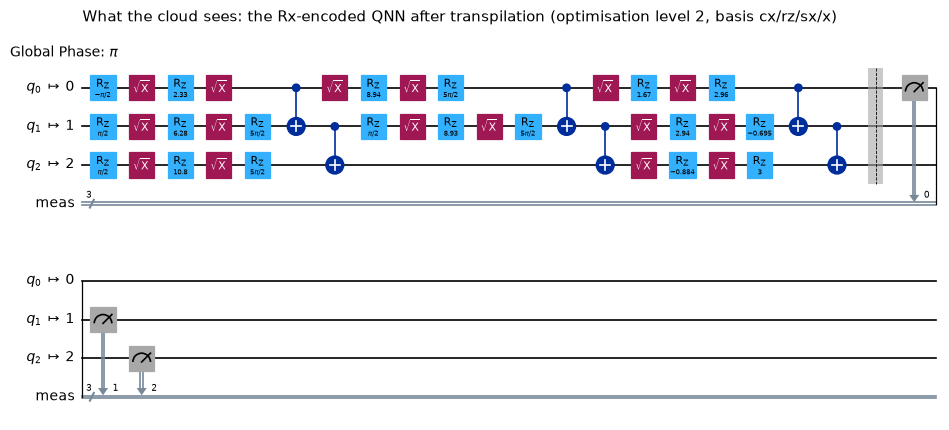

,circuit,qubits,depth,gates,trainable_PQC_parameters,data_parameters
0,Angle encoding,3,11,18,9,3
1,Basis encoding,3,10,16,9,0
2,Amplitude encoding,3,11,16,9,8
3,Angle encoding + defence,3,17,32,9,3
4,"Rx QNN, transpiled",3,21,41,n/a (compiled),n/a (compiled)


In [10]:
demo = dict(n=3, layers=2, start="cx", seed=11)
def n_trainable(spec):
    pq = pqc_circuit(spec["n"], spec["layers"], spec["start"], spec_rng(spec, 1))
    return sum(len(i.operation.params) for i in pq.data)
rows = []
for title, enc, dfd in [("Angle encoding (Rx; Ry and Rz identical with the gate name changed)", "rx", False), ("Basis encoding", "basis", False),
                        ("Amplitude encoding (state preparation box)", "amplitude", False), ("Angle encoding (Rx) with the proposed defence", "rx", True)]:
    sp = {**demo, "enc": enc}
    qc = build_qnn(sp, dfd)
    fig = qc.draw("mpl", fold=30, scale=0.75)
    fig.suptitle(title, fontsize=11); display(fig); plt.close(fig)
    rows.append(dict(circuit=title.split(" (")[0] + (" + defence" if dfd else ""), qubits=qc.num_qubits, depth=qc.depth(), gates=sum(v for k, v in qc.count_ops().items() if k not in ("barrier", "measure")),
                     trainable_PQC_parameters=n_trainable(sp), data_parameters={"rx": demo["n"], "basis": 0, "amplitude": 2 ** demo["n"]}[enc]))
tq = transpile_specs([{**demo, "enc": "rx"}])[0]
fig = tq.draw("mpl", fold=22, scale=0.6, idle_wires=False); fig.suptitle(f"What the cloud sees: the Rx-encoded QNN after transpilation (optimisation level {OPT_LEVEL}, basis cx/rz/sx/x)", fontsize=11); display(fig); plt.close(fig)
rows.append(dict(circuit="Rx QNN, transpiled", qubits=tq.num_qubits, depth=tq.depth(), gates=sum(v for k, v in tq.count_ops().items() if k not in ("barrier", "measure")),
                 trainable_PQC_parameters="n/a (compiled)", data_parameters="n/a (compiled)"))
display(pd.DataFrame(rows))

## 2. The adversary: predicting the encoding from the transpiled circuit

The attacker is a multilayer perceptron with two hidden layers (25 and 10 ReLU neurons) and a softmax over the five encodings, trained with Adam for 100 epochs on z-scored features, exactly as the paper describes.
All the learning is done on the training split; the validation split is only used to draw the paper's Fig. 2 curve; the test split is used once for the metrics. The same features also go to a RandomForest and an
RBF-kernel SVC as classical baselines (they are not in the paper). Chance level is 20 %, because the five classes are balanced.

In [11]:
PAPER_T1 = {"amplitude": (1.00, 1.00, 1.00), "basis": (0.93, 0.81, 0.87), "rx": (0.92, 0.96, 0.94), "ry": (0.93, 0.97, 0.95), "rz": (0.95, 0.98, 0.96)}   # paper Table I: precision, recall, F1

def train_attacker(Xtr, ytr, Xva, yva, seed, epochs=EPOCHS):
    """Paper: z-score, MLP 25-10, ReLU, Adam, 100 iterations, softmax over 5 classes. One epoch per partial_fit call so that Fig. 2 can be drawn."""
    sc = StandardScaler().fit(Xtr)                                  # fitted on the training split only
    clf = MLPClassifier(hidden_layer_sizes=HIDDEN, activation="relu", solver="adam", random_state=seed)
    A, B = sc.transform(Xtr), sc.transform(Xva)
    hist = []
    for ep in range(1, epochs + 1):
        clf.partial_fit(A, ytr, classes=np.arange(5))
        hist.append(dict(epoch=ep, loss=clf.loss_, train_acc=clf.score(A, ytr), val_acc=clf.score(B, yva)))
    return sc, clf, pd.DataFrame(hist)

rows, MAIN = [], {}
for s in SEEDS:
    itr, iva, ite = split_idx(Y_ALL, s)
    t0 = time.time(); sc, clf, hist = train_attacker(X_ALL[itr], Y_ALL[itr], X_ALL[iva], Y_ALL[iva], s)
    pred = clf.predict(sc.transform(X_ALL[ite])); t_mlp = time.time() - t0
    t0 = time.time(); rf = RandomForestClassifier(n_estimators=200, random_state=s, n_jobs=2).fit(sc.transform(X_ALL[itr]), Y_ALL[itr]); p_rf = rf.predict(sc.transform(X_ALL[ite])); t_rf = time.time() - t0
    t0 = time.time(); svc = SVC(kernel="rbf", C=1.0, random_state=s).fit(sc.transform(X_ALL[itr]), Y_ALL[itr]); p_svc = svc.predict(sc.transform(X_ALL[ite])); t_svc = time.time() - t0
    rows.append(dict(seed=s, MLP=accuracy_score(Y_ALL[ite], pred), RandomForest=accuracy_score(Y_ALL[ite], p_rf), SVC_rbf=accuracy_score(Y_ALL[ite], p_svc),
                     sec_MLP=t_mlp, sec_RF=t_rf, sec_SVC=t_svc))
    if s == SEED:
        MAIN = dict(sc=sc, clf=clf, hist=hist, itr=itr, iva=iva, ite=ite, pred=pred, rf=rf, svc=svc)
RES = pd.DataFrame(rows)
summary = pd.DataFrame({"mean test accuracy": RES[["MLP", "RandomForest", "SVC_rbf"]].mean(), "std over seeds": RES[["MLP", "RandomForest", "SVC_rbf"]].std(ddof=0)})
summary.loc["majority / chance"] = [0.2, 0.0]
display(RES.round(3)); display(summary.round(3))
ITE = MAIN["ite"]; Y_TE = Y_ALL[ITE]

,seed,MLP,RandomForest,SVC_rbf,sec_MLP,sec_RF,sec_SVC
0,42,0.816,0.814,0.816,17.988,10.676,30.101
1,43,0.811,0.820,0.809,15.910,7.653,26.901
2,44,0.810,0.823,0.818,17.592,6.706,30.477
3,45,0.815,0.816,0.812,20.082,7.181,30.232
4,46,0.813,0.819,0.813,17.837,6.625,31.293


,mean test accuracy,std over seeds
MLP,0.813,0.002
RandomForest,0.818,0.003
SVC_rbf,0.813,0.003
majority / chance,0.200,0.000


### Table I redrawn: precision, recall and F1 per encoding (main seed)

,encoding,precision,recall,F1,support,paper precision,paper recall,paper F1
0,Amplitude,1.00,1.00,1.00,900,1.00,1.00,1.00
1,Basis,0.92,0.58,0.71,900,0.93,0.81,0.87
2,Angle Rx,0.71,0.82,0.76,900,0.92,0.96,0.94
3,Angle Ry,0.72,0.81,0.76,900,0.93,0.97,0.95
4,Angle Rz,0.80,0.86,0.83,900,0.95,0.98,0.96


accuracy 0.816 (paper 0.94) | macro F1 0.813 (paper 0.94) | weighted F1 0.813 (paper 0.94)
Task: 5-class prediction, so there is no single 'attack' positive class; the confusion matrix below shows where the classes are mixed up.


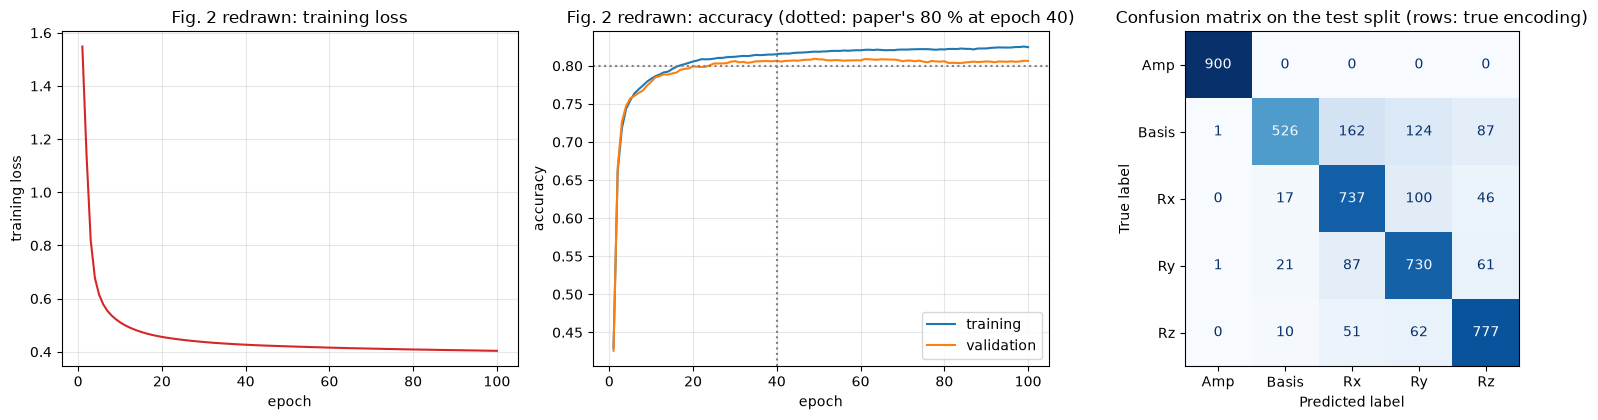

validation accuracy at epoch 40: 0.807 | training accuracy at epoch 100: 0.825 | training loss 1.55 -> 0.40 | monotone decrease: True (share of epochs with a decrease or a tie: 1.00)


In [12]:
rep = classification_report(Y_TE, MAIN["pred"], target_names=ENCODINGS, output_dict=True, digits=3)
T1 = pd.DataFrame({"encoding": [ENC_LABEL[e] for e in ENCODINGS],
                   "precision": [rep[e]["precision"] for e in ENCODINGS], "recall": [rep[e]["recall"] for e in ENCODINGS], "F1": [rep[e]["f1-score"] for e in ENCODINGS],
                   "support": [int(rep[e]["support"]) for e in ENCODINGS],
                   "paper precision": [PAPER_T1[e][0] for e in ENCODINGS], "paper recall": [PAPER_T1[e][1] for e in ENCODINGS], "paper F1": [PAPER_T1[e][2] for e in ENCODINGS]})
display(T1.round(2))
print(f"accuracy {rep['accuracy']:.3f} (paper 0.94) | macro F1 {rep['macro avg']['f1-score']:.3f} (paper 0.94) | weighted F1 {rep['weighted avg']['f1-score']:.3f} (paper 0.94)")
print("Task: 5-class prediction, so there is no single 'attack' positive class; the confusion matrix below shows where the classes are mixed up.")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
H = MAIN["hist"]
axes[0].plot(H.epoch, H.loss, color="#d62728"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training loss"); axes[0].set_title("Fig. 2 redrawn: training loss")
axes[1].plot(H.epoch, H.train_acc, label="training"); axes[1].plot(H.epoch, H.val_acc, label="validation"); axes[1].axvline(40, color="grey", ls=":"); axes[1].axhline(0.8, color="grey", ls=":")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Fig. 2 redrawn: accuracy (dotted: paper's 80 % at epoch 40)"); axes[1].legend()
ConfusionMatrixDisplay(confusion_matrix(Y_TE, MAIN["pred"]), display_labels=["Amp", "Basis", "Rx", "Ry", "Rz"]).plot(ax=axes[2], colorbar=False, cmap="Blues")
axes[2].set_title("Confusion matrix on the test split (rows: true encoding)"); axes[2].grid(False)
plt.tight_layout(); plt.show()
EP40 = H.loc[H.epoch == 40, "val_acc"].item(); FIRST_LOSS, LAST_LOSS = H.loss.iloc[0], H.loss.iloc[-1]
print(f"validation accuracy at epoch 40: {EP40:.3f} | training accuracy at epoch {EPOCHS}: {H.train_acc.iloc[-1]:.3f} | training loss {FIRST_LOSS:.2f} -> {LAST_LOSS:.2f} | monotone decrease: {bool((H.loss.diff().dropna() <= 1e-3).mean() > 0.9)} (share of epochs with a decrease or a tie: {(H.loss.diff().dropna() <= 1e-3).mean():.2f})")

### Which features carry the fingerprint? (extra, not in the paper)

A feature-importance ranking from the RandomForest, and an ablation that removes the six "front" features (our addition for the first gates on each qubit) and retrains the paper's MLP. If the front features matter, the encoding is mostly visible *at the start of the circuit*, as intuition suggests.

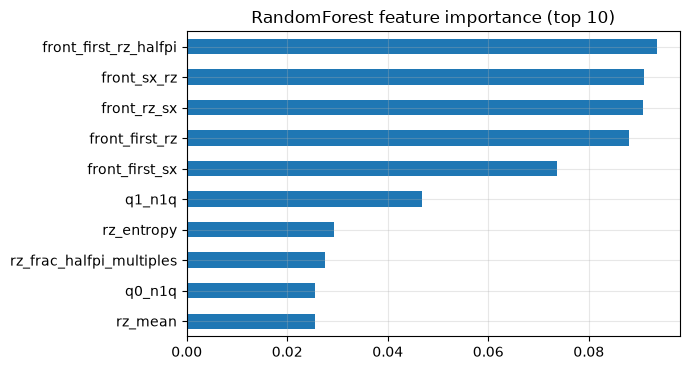

MLP test accuracy with all 33 features: 0.816 | without the 6 front features: 0.652


In [13]:
imp = pd.Series(MAIN["rf"].feature_importances_, index=NAMES).sort_values(ascending=False)
keep = [i for i, f in enumerate(NAMES) if f not in FRONT_FEATURES]
sc_a, clf_a, _ = train_attacker(X_ALL[MAIN["itr"]][:, keep], Y_ALL[MAIN["itr"]], X_ALL[MAIN["iva"]][:, keep], Y_ALL[MAIN["iva"]], SEED)
ACC_NO_FRONT = accuracy_score(Y_TE, clf_a.predict(sc_a.transform(X_ALL[ITE][:, keep])))
fig, ax = plt.subplots(figsize=(7, 3.8))
imp.head(10)[::-1].plot.barh(ax=ax, color="#1f77b4"); ax.set_title("RandomForest feature importance (top 10)"); plt.tight_layout(); plt.show()
print(f"MLP test accuracy with all {len(NAMES)} features: {accuracy_score(Y_TE, MAIN['pred']):.3f} | without the {len(FRONT_FEATURES)} front features: {ACC_NO_FRONT:.3f}")

## 3. Accuracy against the number of qubits (Fig. 3)

The paper repeats the attack for 3 to 14 qubits (one feature per qubit; features = 27 + 2 x qubits, i.e. 33 to 55). Amplitude encoding of n qubits compiles to roughly 4^n gates, so we stop at 6 (FAST) or 8 qubits (full). For each size we generate a fresh set of circuits, train the
attacker on it and test it, with and without the defence (the defended test circuits are the *same* circuits rebuilt with the defence).

,qubits,features,circuits,test_accuracy,accuracy_with_defence
0,3,33,3000,0.787,0.490
1,4,35,3000,0.778,0.697
2,5,37,3000,0.805,0.695
3,6,39,3000,0.763,0.557
4,7,41,3000,0.767,0.452
5,8,43,3000,0.773,0.505


sweep took 1361 s


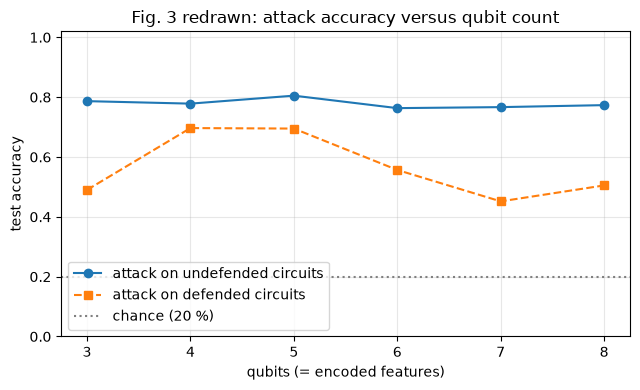

features at 3 / 14 / 100 qubits by Eq. 1: 33 55 227


In [14]:
SWEEP = []
t_sweep = time.time()
for n in SWEEP_QUBITS:
    sp = make_specs(n, PER_CLASS_SWEEP, SEED + n)
    X = build_features(sp, tag=f"sweep{n}")
    y = np.array([ENCODINGS.index(s["enc"]) for s in sp])
    assert X.shape[1] == 27 + 2 * n, (X.shape, n)                      # Eq. 1
    itr, iva, ite = split_idx(y, SEED)
    sc, clf, _ = train_attacker(X[itr], y[itr], X[iva], y[iva], SEED)
    acc = accuracy_score(y[ite], clf.predict(sc.transform(X[ite])))
    Xd = build_features([sp[i] for i in ite], defended=True, tag=f"sweepdef{n}")
    acc_def = accuracy_score(y[ite], clf.predict(sc.transform(Xd)))
    SWEEP.append(dict(qubits=n, features=X.shape[1], circuits=len(sp), test_accuracy=acc, accuracy_with_defence=acc_def))
SWEEP = pd.DataFrame(SWEEP)
display(SWEEP.round(3)); print(f"sweep took {time.time() - t_sweep:.0f} s")
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(SWEEP.qubits, SWEEP.test_accuracy, "o-", label="attack on undefended circuits"); ax.plot(SWEEP.qubits, SWEEP.accuracy_with_defence, "s--", label="attack on defended circuits")
ax.axhline(0.2, color="grey", ls=":", label="chance (20 %)"); ax.set_xlabel("qubits (= encoded features)"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.02)
ax.set_title("Fig. 3 redrawn: attack accuracy versus qubit count"); ax.legend(); plt.tight_layout(); plt.show()
print("features at 3 / 14 / 100 qubits by Eq. 1:", 27 + 2 * 3, 27 + 2 * 14, 27 + 2 * 100)

## 4. Why the compiler matters: the same attack at optimisation levels 0 to 3 (extra, not in the paper)

The paper says the circuits were transpiled on `GenericBackendV2` but not with which optimisation level. That setting decides how much of the encoding survives: at level 0 the compiler only translates gates into the device's basis, so the data-loading block stays intact;
from level 1 on it *merges* neighbouring single-qubit gates, so the encoding rotation melts into the first PQC rotation and loses its shape. The next table repeats the 3-qubit attack and the defence for each level on the same specifications.

,optimisation_level,accuracy,accuracy_with_defence,F1 Amplitude,F1 Basis,F1 Angle Rx,F1 Angle Ry,F1 Angle Rz
0,0,0.850,0.776,1.000,0.964,0.670,0.632,0.990
1,1,0.794,0.502,1.000,0.722,0.741,0.724,0.777
2,2,0.798,0.500,1.000,0.706,0.718,0.731,0.819
3,3,0.798,0.496,0.995,0.713,0.716,0.736,0.814


took 213 s


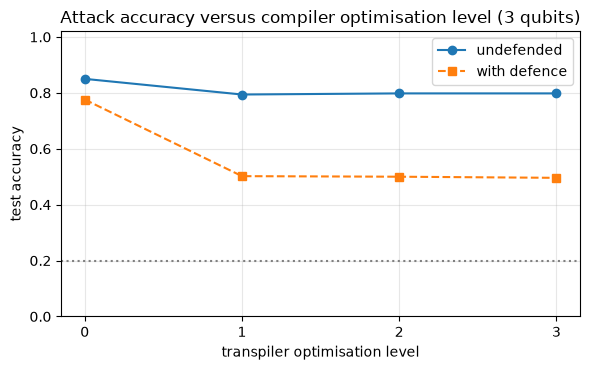

In [15]:
OPTR = []
t_opt = time.time()
sp_o = make_specs(N_QUBITS, PER_CLASS_OPT, SEED + 100)
y_o = np.array([ENCODINGS.index(s["enc"]) for s in sp_o])
for lev in OPT_SWEEP:
    X = build_features(sp_o, opt=lev, tag=f"opt{lev}")
    itr, iva, ite = split_idx(y_o, SEED)
    sc, clf, _ = train_attacker(X[itr], y_o[itr], X[iva], y_o[iva], SEED)
    pr = clf.predict(sc.transform(X[ite]))
    Xd = build_features([sp_o[i] for i in ite], defended=True, opt=lev, tag=f"optdef{lev}")
    prd = clf.predict(sc.transform(Xd))
    f1 = classification_report(y_o[ite], pr, target_names=ENCODINGS, output_dict=True)
    OPTR.append(dict(optimisation_level=lev, accuracy=accuracy_score(y_o[ite], pr), accuracy_with_defence=accuracy_score(y_o[ite], prd),
                     **{f"F1 {ENC_LABEL[e]}": f1[e]["f1-score"] for e in ENCODINGS}))
OPTR = pd.DataFrame(OPTR); display(OPTR.round(3)); print(f"took {time.time() - t_opt:.0f} s")
fig, ax = plt.subplots(figsize=(6, 3.8))
ax.plot(OPTR.optimisation_level, OPTR.accuracy, "o-", label="undefended"); ax.plot(OPTR.optimisation_level, OPTR.accuracy_with_defence, "s--", label="with defence")
ax.axhline(0.2, color="grey", ls=":"); ax.set_xticks(OPT_SWEEP); ax.set_xlabel("transpiler optimisation level"); ax.set_ylabel("test accuracy"); ax.set_ylim(0, 1.02); ax.legend()
ax.set_title("Attack accuracy versus compiler optimisation level (3 qubits)"); plt.tight_layout(); plt.show()

## 5. The defence: a cloaking layer between the encoding and the PQC

The layer is built exactly as in the paper: `H` and `RX(theta_i)` (theta_i uniform in [-pi, pi]) on every qubit, then CNOTs on the pairs (0,1), (2,3), ...; a barrier; then the exact inverse (the same CNOTs, `RX(-theta_i)`, `H`). Because the circuit continues with the PQC *after* the inverse, its output must be unchanged.
We check that first with state vectors (no sampling, no noise), then measure what the cloud's classifier makes of the defended circuits and what the layer costs in depth.

### 5.1 The defence changes nothing about the circuit's function

In [16]:
eq_specs = make_specs(N_QUBITS, 4, 999, layers=3)           # 20 circuits: 4 per encoding
n_ok = 0
for s in eq_specs:
    a, b = build_qnn(s, False, measure=False), build_qnn(s, True, measure=False)
    assert Statevector(a).equiv(Statevector(b)), f"defence changed the output state for {s}"          # equal up to a global phase
    n_ok += 1
print(f"{n_ok} of {len(eq_specs)} circuits: the output state with the defence equals the output state without it (up to a global phase).")
# also after transpilation (routing and optimisation must not change the unitary either): compare the full unitaries of transpiled circuits
n_ok2 = 0
for s in eq_specs[:10]:
    ta = transpile(build_qnn(s, False, measure=False), get_backend(N_QUBITS), optimization_level=OPT_LEVEL, seed_transpiler=SEED)
    tb = transpile(build_qnn(s, True, measure=False), get_backend(N_QUBITS), optimization_level=OPT_LEVEL, seed_transpiler=SEED)
    n_ok2 += bool(Operator.from_circuit(ta).equiv(Operator.from_circuit(tb)))
print(f"{n_ok2} of 10 transpiled pairs have identical unitaries (with the final qubit permutation accounted for).")

20 of 20 circuits: the output state with the defence equals the output state without it (up to a global phase).


10 of 10 transpiled pairs have identical unitaries (with the final qubit permutation accounted for).


### 5.2 What the cloud's classifier says about defended circuits

,recall without defence,recall with defence
amplitude,1.000,1.000
basis,0.584,0.211
rx,0.819,0.551
ry,0.811,0.164
rz,0.863,0.637


attack accuracy without defence 0.816 -> with defence 0.513 (paper: 0.95 -> 0.42; chance 0.20) [105 s]
what the undefended classifier predicts for defended circuits (columns) given the true encoding (rows):


,pred amplitude,pred basis,pred rx,pred ry,pred rz
true amplitude,900,0,0,0,0
true basis,3,190,114,57,536
true rx,16,75,496,107,206
true ry,12,79,482,148,179
true rz,1,177,97,52,573


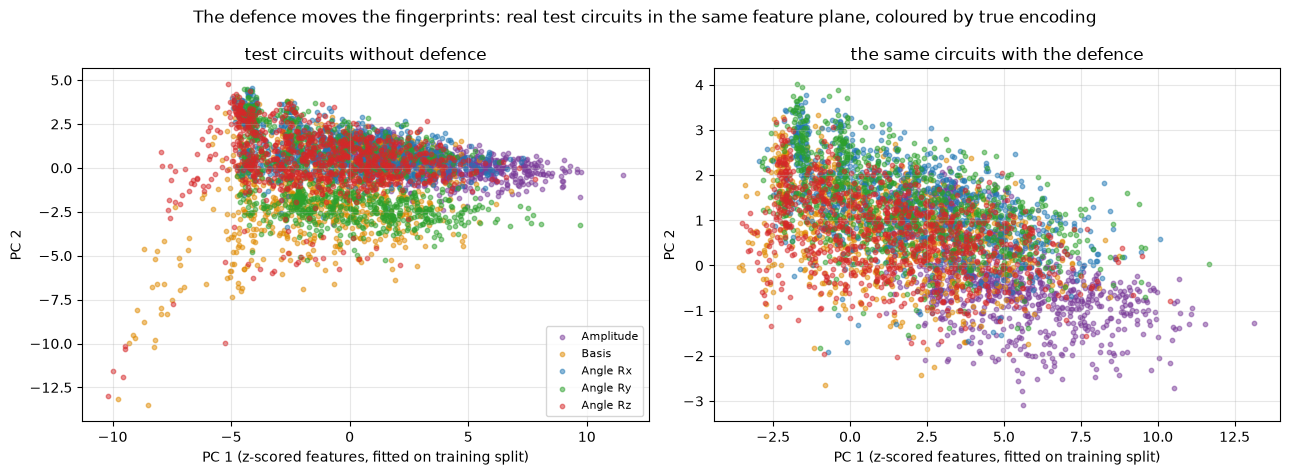

In [17]:
t0 = time.time()
SP_TE = [SPECS[i] for i in ITE]
X_TE_DEF = build_features(SP_TE, defended=True, tag="main_test_def")           # the SAME test circuits, rebuilt with the defence
pred_def = MAIN["clf"].predict(MAIN["sc"].transform(X_TE_DEF))
ACC_DEF = accuracy_score(Y_TE, pred_def)
rec_def = {e: float((pred_def[Y_TE == c] == c).mean()) for c, e in enumerate(ENCODINGS)}
rec_undef = {e: float((MAIN["pred"][Y_TE == c] == c).mean()) for c, e in enumerate(ENCODINGS)}
DEF_TAB = pd.DataFrame({"recall without defence": rec_undef, "recall with defence": rec_def}).round(3)
display(DEF_TAB)
print(f"attack accuracy without defence {accuracy_score(Y_TE, MAIN['pred']):.3f} -> with defence {ACC_DEF:.3f} (paper: 0.95 -> 0.42; chance 0.20) [{time.time() - t0:.0f} s]")
print("what the undefended classifier predicts for defended circuits (columns) given the true encoding (rows):")
display(pd.DataFrame(confusion_matrix(Y_TE, pred_def, labels=range(5)), index=[f"true {e}" for e in ENCODINGS], columns=[f"pred {e}" for e in ENCODINGS]))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
P0, P1 = pca_z.transform(sc_vis.transform(X_ALL[ITE])), pca_z.transform(sc_vis.transform(X_TE_DEF))
for c, e in enumerate(ENCODINGS):
    axes[0].scatter(P0[Y_TE == c, 0], P0[Y_TE == c, 1], s=10, alpha=0.5, color=COLORS[e], label=ENC_LABEL[e])
    axes[1].scatter(P1[Y_TE == c, 0], P1[Y_TE == c, 1], s=10, alpha=0.5, color=COLORS[e], label=ENC_LABEL[e])
axes[0].set_title("test circuits without defence"); axes[1].set_title("the same circuits with the defence"); axes[0].legend(fontsize=8)
for ax in axes: ax.set_xlabel("PC 1 (z-scored features, fitted on training split)"); ax.set_ylabel("PC 2")
lim = (min(P0.min(0).min(), P1.min(0).min()), max(P0.max(0).max(), P1.max(0).max()))
plt.suptitle("The defence moves the fingerprints: real test circuits in the same feature plane, coloured by true encoding"); plt.tight_layout(); plt.show()

### 5.3 An adaptive adversary (extra, not in the paper)

The paper tests the *old* classifier on defended circuits. A cloud that knows (or guesses) that the defence is in use can simply train on defended circuits. The next cell trains the same MLP on defended training circuits
(a subset, to keep it cheap) and compares it with an undefended classifier trained on the same number of circuits.

In [18]:
t0 = time.time()
itr = MAIN["itr"]
sub = np.concatenate([itr[Y_ALL[itr] == c][:ADAPT_PER_CLASS] for c in range(5)])
n_va = max(len(sub) // 5, 5)
rs = np.random.default_rng(SEED).permutation(len(sub)); sub = sub[rs]
tr_i, va_i = sub[n_va:], sub[:n_va]
X_sub_def = build_features([SPECS[i] for i in sub], defended=True, tag="adapt_def")          # defended versions of the same specs, in the order of `sub`
X_tr_d, X_va_d = X_sub_def[n_va:], X_sub_def[:n_va]
sc_d, clf_d, _ = train_attacker(X_tr_d, Y_ALL[tr_i], X_va_d, Y_ALL[va_i], SEED)
ACC_ADAPT = accuracy_score(Y_TE, clf_d.predict(sc_d.transform(X_TE_DEF)))
sc_u, clf_u, _ = train_attacker(X_ALL[tr_i], Y_ALL[tr_i], X_ALL[va_i], Y_ALL[va_i], SEED)
ACC_SMALL = accuracy_score(Y_TE, clf_u.predict(sc_u.transform(X_ALL[ITE])))
print(f"{len(tr_i)} training circuits each. Undefended classifier on undefended test circuits: {ACC_SMALL:.3f} | classifier trained on defended circuits, tested on defended circuits: {ACC_ADAPT:.3f} [{time.time() - t0:.0f} s]")

2000 training circuits each. Undefended classifier on undefended test circuits: 0.789 | classifier trained on defended circuits, tested on defended circuits: 0.604 [101 s]


### 5.4 Depth overhead (Table II)

,encoding,original,obfuscated,abs_increase,increase_pct,paper_original,paper_obfuscated,paper_increase_pct
0,Amplitude,78.3,88.4,10.1,12.9,95.2,101.1,6.2
1,Basis,50.8,64.4,13.6,26.8,67.6,74.1,9.7
2,Angle Rx,52.8,66.8,13.9,26.4,70.2,76.1,8.4
3,Angle Ry,53.3,67.2,14.0,26.2,69.2,76.1,10.0
4,Angle Rz,51.3,65.5,14.3,27.8,67.7,74.1,9.5


mean depth increase over the five encodings: 24.0 % (paper: about 8.5 %) | 4000 circuits per setting, 175 s


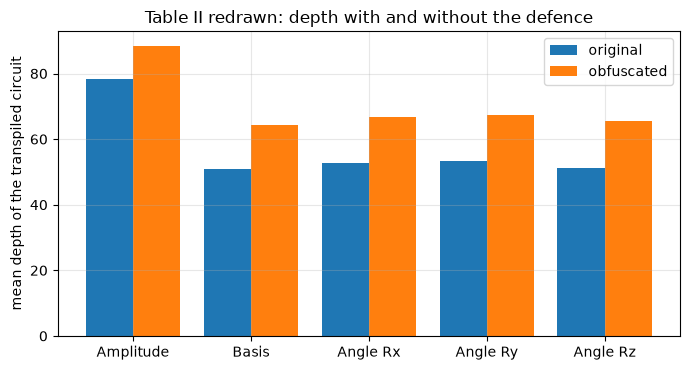

In [19]:
PAPER_T2 = {"amplitude": (95.2, 101.1, 6.2), "basis": (67.6, 74.1, 9.7), "rx": (70.2, 76.1, 8.4), "ry": (69.2, 76.1, 10.0), "rz": (67.7, 74.1, 9.5)}   # original, obfuscated, increase in %
t0 = time.time()
sp5 = make_specs(N_QUBITS, PER_CLASS_DEPTH, SEED + 7, layers=5)             # 5-layer PQC, as in Table II
d_orig = np.array([t.depth() for t in transpile_specs(sp5)]); d_def = np.array([t.depth() for t in transpile_specs(sp5, defended=True)])
enc5 = np.array([s["enc"] for s in sp5])
T2 = pd.DataFrame([dict(encoding=ENC_LABEL[e], original=d_orig[enc5 == e].mean(), obfuscated=d_def[enc5 == e].mean(),
                        abs_increase=d_def[enc5 == e].mean() - d_orig[enc5 == e].mean(), increase_pct=100 * (d_def[enc5 == e].mean() / d_orig[enc5 == e].mean() - 1),
                        paper_original=PAPER_T2[e][0], paper_obfuscated=PAPER_T2[e][1], paper_increase_pct=PAPER_T2[e][2]) for e in ENCODINGS])
display(T2.round(1))
MEAN_OVERHEAD = float(T2.increase_pct.mean())
print(f"mean depth increase over the five encodings: {MEAN_OVERHEAD:.1f} % (paper: about 8.5 %) | {len(sp5)} circuits per setting, {time.time() - t0:.0f} s")
fig, ax = plt.subplots(figsize=(7, 3.8)); xx = np.arange(5)
ax.bar(xx - 0.2, T2.original, 0.4, label="original"); ax.bar(xx + 0.2, T2.obfuscated, 0.4, label="obfuscated")
ax.set_xticks(xx); ax.set_xticklabels(T2.encoding); ax.set_ylabel("mean depth of the transpiled circuit"); ax.set_title("Table II redrawn: depth with and without the defence"); ax.legend()
plt.tight_layout(); plt.show()

## 6. Side by side with the paper

For every claim that the notebook can test, the table shows the paper's value, ours and a verdict. The rule: a number is **reproduced** when it is within 0.02 (2 accuracy points; 0.02 for precision, recall and F1) of the paper's,
otherwise **exceeded** or **not reached** with the signed gap (in the direction that is better for the *attacker*; for the defence rows lower attacker accuracy is better for the *defender*, and for the depth rows a smaller overhead is better). Depth values
are compared with a 10 % relative tolerance and depth increases with 2 percentage points. The loss values of Fig. 2 are compared with a tolerance of 0.1. Paper numbers are those printed in the text and in the two tables; the three figures are only described in words.

In [20]:
def verdict(paper, ours, tol, lower_better=False, rel=False):
    if ours is None or (isinstance(ours, float) and np.isnan(ours)): return "cannot be checked"
    gap = ours - paper
    scale = abs(paper) if rel else 1.0
    if abs(gap) <= tol * scale: return "reproduced"
    better = gap < 0 if lower_better else gap > 0
    return ("exceeded" if better else "not reached") + f" ({gap:+.3f})"

rows = []
def add(claim, paper, ours, tol=0.02, **kw):
    rows.append(dict(claim=claim, paper=paper, notebook=(round(float(ours), 3) if ours is not None and ours == ours else np.nan), verdict=verdict(paper, ours, tol, **kw)))

acc_mlp = RES["MLP"].mean()
add(f"C1 attack accuracy, 3 qubits, mean over {len(SEEDS)} seed(s) (Table I)", 0.94, acc_mlp)
add("C1 attack accuracy, main seed (Table I)", 0.94, rep["accuracy"])
add("C1 'about 95 %' of the encodings predicted correctly (text)", 0.95, acc_mlp)
add("C1 macro-average F1 (Table I)", 0.94, rep["macro avg"]["f1-score"])
add("C1 weighted-average F1 (Table I)", 0.94, rep["weighted avg"]["f1-score"])
for e in ENCODINGS:
    for k, nm in enumerate(["precision", "recall", "f1-score"]):
        add(f"C2 {ENC_LABEL[e]} {nm} (Table I)", PAPER_T1[e][k], rep[e][nm])
add("C3 validation accuracy at epoch 40 (Fig. 2: 'reaches 80 %')", 0.80, EP40)
add(f"C3 training accuracy at epoch {EPOCHS} (Fig. 2: 'about 90 %')", 0.90, H.train_acc.iloc[-1])
add("C3 training loss at the first epoch (Fig. 2: 1.2)", 1.2, FIRST_LOSS, tol=0.1, lower_better=True)
add(f"C3 training loss at epoch {EPOCHS} (Fig. 2: 0.2)", 0.2, LAST_LOSS, tol=0.1, lower_better=True)
add("C4 features at 3 qubits (Eq. 1)", 33, X_ALL.shape[1], tol=0)
add("C4 features at 14 qubits (Eq. 1; length of our name list)", 55, len(feature_names(14)), tol=0)
add("C4 features at 100 qubits (Eq. 1)", 227, len(feature_names(100)), tol=0)
s3 = SWEEP.loc[SWEEP.qubits == 3, "test_accuracy"]
add("C5 accuracy at 3 qubits in the sweep (Fig. 3: 94 %)", 0.94, float(s3.iloc[0]) if len(s3) else np.nan)
big = SWEEP.iloc[-1]
add(f"C5 accuracy at the largest qubit count we can run, {int(big.qubits)} qubits (paper: 95 % at 14 qubits)", 0.95, float(big.test_accuracy))
slope = np.polyfit(SWEEP.qubits, SWEEP.test_accuracy, 1)[0] if len(SWEEP) > 1 else np.nan
rows.append(dict(claim="C5 accuracy does not degrade as qubits are added (slope of accuracy vs qubits, per qubit)", paper=">= 0", notebook=round(float(slope), 4),
                 verdict="reproduced" if slope >= -0.005 else f"not reached ({slope:+.4f} per qubit)"))
add("C6 attack accuracy with the defence, 3 qubits (Fig. 3: 'average of 42 %')", 0.42, ACC_DEF, lower_better=True)
add(f"C6 mean attack accuracy with the defence over the qubit sweep ({SWEEP.qubits.min()}..{SWEEP.qubits.max()} qubits)", 0.42, float(SWEEP.accuracy_with_defence.mean()), lower_better=True)
add("C7 mean depth increase of the defence, five encodings (Table II)", 8.5, MEAN_OVERHEAD, tol=2.0, lower_better=True)
for _, r in T2.iterrows():
    add(f"C7 depth increase in %, {r.encoding} (Table II)", r.paper_increase_pct, r.increase_pct, tol=2.0, lower_better=True)
    add(f"C7 original depth, {r.encoding} (Table II)", r.paper_original, r.original, tol=0.10, rel=True)
rows.append(dict(claim="C8 the defence leaves the circuit's output state unchanged (state-vector check, 20 circuits)", paper="qualitative", notebook=float(n_ok / len(eq_specs)), verdict="reproduced" if n_ok == len(eq_specs) else "not reached"))
add("X1 extra: RandomForest on the same features (accuracy, no paper value)", np.nan, RES["RandomForest"].mean(), tol=0)
add("X2 extra: SVC (rbf) on the same features (accuracy, no paper value)", np.nan, RES["SVC_rbf"].mean(), tol=0)
add("X3 extra: adaptive adversary trained on defended circuits (accuracy, no paper value)", np.nan, ACC_ADAPT, tol=0)
COMPARE = pd.DataFrame(rows)
COMPARE.loc[COMPARE.paper.isna(), "verdict"] = "extra measure (no paper value)"
pd.set_option("display.max_rows", 200)
display(COMPARE)
print(COMPARE.verdict.str.split(" ").str[0].value_counts().to_string())

,claim,paper,notebook,verdict
0,"C1 attack accuracy, 3 qubits, mean over 5 seed(s) (Table I)",0.94,0.8130,not reached (-0.127)
1,"C1 attack accuracy, main seed (Table I)",0.94,0.8160,not reached (-0.124)
2,C1 'about 95 %' of the encodings predicted correctly (text),0.95,0.8130,not reached (-0.137)
3,C1 macro-average F1 (Table I),0.94,0.8130,not reached (-0.127)
4,C1 weighted-average F1 (Table I),0.94,0.8130,not reached (-0.127)
5,C2 Amplitude precision (Table I),1.0,0.9980,reproduced
6,C2 Amplitude recall (Table I),1.0,1.0000,reproduced
7,C2 Amplitude f1-score (Table I),1.0,0.9990,reproduced
8,C2 Basis precision (Table I),0.93,0.9160,reproduced
9,C2 Basis recall (Table I),0.81,0.5840,not reached (-0.226)


verdict
not           34
reproduced    10
extra          3


In [21]:
# Auto-generated summary of this run (so the text below never disagrees with the numbers above)
n_rep = COMPARE.verdict.str.startswith("reproduced").sum(); n_exc = COMPARE.verdict.str.startswith("exceeded").sum(); n_nr = COMPARE.verdict.str.startswith("not reached").sum()
print(f"{len(COMPARE)} rows: {n_rep} reproduced, {n_exc} exceeded, {n_nr} not reached.")
print("Run mode:", f"FAST_MODE ({PER_CLASS} circuits per encoding, {len(SEEDS)} seeds, qubits {SWEEP_QUBITS})" if FAST_MODE else f"full size ({PER_CLASS} circuits per encoding = {5 * PER_CLASS}, {len(SEEDS)} seeds, qubits {SWEEP_QUBITS})")
print(f"Transpiler optimisation level of the main experiment: {OPT_LEVEL}")
print(f"Attack accuracy (MLP): {acc_mlp:.3f} +- {RES['MLP'].std(ddof=0):.3f} over seeds; with the defence {ACC_DEF:.3f}; depth overhead {MEAN_OVERHEAD:.1f} %.")
print("Attack accuracy by optimisation level (undefended / defended):", {int(r.optimisation_level): (round(r.accuracy, 2), round(r.accuracy_with_defence, 2)) for _, r in OPTR.iterrows()})

47 rows: 10 reproduced, 0 exceeded, 34 not reached.
Run mode: full size (4500 circuits per encoding = 22500, 5 seeds, qubits [3, 4, 5, 6, 7, 8])
Transpiler optimisation level of the main experiment: 2
Attack accuracy (MLP): 0.813 +- 0.002 over seeds; with the defence 0.513; depth overhead 24.0 %.
Attack accuracy by optimisation level (undefended / defended): {0: (np.float64(0.85), np.float64(0.78)), 1: (np.float64(0.79), np.float64(0.5)), 2: (np.float64(0.8), np.float64(0.5)), 3: (np.float64(0.8), np.float64(0.5))}


## 7. Reading the paper critically

**What the paper shows convincingly (and our full run confirms).**
* The compiled circuit leaks the *kind* of data loading. Amplitude encoding is recognised essentially perfectly (precision, recall and F1 of 1.00, as in Table I), because a state-preparation block compiles to dozens of gates that look nothing like a rotation or an `X`.
  The other four encodings are recognised far above the 20 % chance level (about 81 % overall), and the attack still works for 3 to 8 qubits (about 76 to 81 %, Section 3). The feature count follows `27 + 2 x qubits` exactly.
* The defence does what it is built for in the sense of the paper's test: the undefended classifier drops from about 81 % to about 51 % on the same circuits with the defence, the circuit's output state is unchanged (checked with state vectors, Section 5.1), and the layer costs extra depth.

**Where the claims need care.**
1. *The headline "about 95 %" is not reached here.* Our MLP reaches about 81 % at 3 qubits (5 seeds, standard deviation 0.002); a RandomForest and an RBF SVC on the same features are equally good (about 82 % and 81 %), so the gap to 94 % is not an optimiser problem of the 25-10 network. The missing points are
   the three angle encodings against each other and `Basis`: after optimisation the encoding rotation is merged with the next PQC rotation, and `Rz(x)` acting on `|0>` is only a phase. Which of Rx, Ry or Rz was used is then hardly recoverable from any feature. The paper reports Rx/Ry/Rz F1 of 0.94 to 0.96; we get 0.76 to 0.83.
   The 27 features are not listed in the paper, so a better feature set might close part of the gap; our ablation (Section 2) shows that the "front" features, which read the first gates on each qubit, are worth about 16 accuracy points.
2. *The number depends on a setting the paper does not state: the compiler's optimisation level.* Section 4 shows 85 % at level 0 (no optimisation, the encoding block survives) and about 80 % at levels 1 to 3; Qiskit's default (level 2), which we use, is the middle of that range. Whether the authors used a different level, a different PQC family, a different feature
   list or measured something else, we cannot tell from the text.
3. *The defence works because the compiler merges gates, and only then.* At optimisation level 0 the defence barely matters (the attack keeps about 78 %), because the encoding gates stay at the front of the circuit. At levels 1 to 3 the random `RX(theta)` and the Hadamard are merged with the encoding gates in front of them, which hides the encoding.
   So the defence is a statement about one compiler's behaviour, not a cryptographic guarantee. We reach 51 % under defence against the paper's 42 % (not reached for the defender, by about 9 points).
4. *Retraining defeats it more easily than the paper suggests.* The paper tests only the classifier trained on undefended circuits. An adversary who trains on defended circuits (Section 5.3, not in the paper) reaches 60 % with only 2 000 training circuits, against 79 % for an undefended classifier of the same size: the defence costs the adversary accuracy but is far from the "near-random" level of the abstract.
   Also, the paper's "near-random chance 42 %" is not near random for five classes (20 %).
5. *Depth overhead is much larger here.* We measure +24 % (about +14 gates deep for the angle and basis encodings) against the paper's +8.5 % (about +6). Our original depths (51 to 78) are lower than the paper's (68 to 95), so the same absolute layer costs a bigger share, but the absolute increase is also more than twice the paper's. Because a barrier separates
   the obfuscation from its inverse, nothing can cancel across it; a smaller increase would need the compiler to merge more of the layer than in our setting. The paper does not say where exactly the barrier sits or how the layer was transpiled.
6. *Internal inconsistencies of the paper.* The text calls Fig. 2's training accuracy "90 %" while Table I gives a test accuracy of 94 % (test above training); the loss falls to 0.2 with only 90 % training accuracy; the abstract's "about 95 %" and Table I's 0.94 differ; "18 000 circuits" and 4 500 test circuits only fit together as 22 500 in total, which is what we assumed.
7. *Threat-model realism.* The attack needs white-box access to the circuit and a labelled training set of circuits made with the same compiler and PQC family as the victim's. An adversary can generate that locally, which is why it is plausible, but the victim's PQC and hardware layout would not be known exactly, and the paper does not test a distribution shift
   (train on one PQC family, test on another). Identifying the encoding type is also only a first step: the paper shows no data extraction.
8. *Scale.* The paper's 14-qubit points could not be run here (amplitude encoding of 14 qubits compiles to about 4^14 gates); our sweep stops at 8 qubits.

## 8. Exercises
1. **Compiler level.** Re-run Section 1 with `OPT_LEVEL = 0` and then `3`. How do the confusion matrix and the 2-D scatter change? Which of the six "front" features survive at level 3? Explain why a single-qubit `Rz` encoding cannot be recovered once it is merged with the following rotation.
2. **A simpler or a richer feature set.** Remove the six front features and then add your own (for example the exact sequence of gate names on each qubit's first four gates). Is the 25-10 MLP the best attacker, or does a gradient-boosted tree beat it on the same data?
3. **`initialize` instead of `prepare_state`.** Change `encoding_circuit` so amplitude encoding uses `qc.initialize(...)`. Which new instruction appears in the transpiled circuit and what happens to the amplitude row of the confusion matrix? What does that tell you about "perfect" classification?
4. **A stronger defence.** The paper's layer has a fixed shape (H, RX, CNOT pairs), so a cloud that trains on defended circuits can still learn it (Section 5.3). Design a layer with a random *number* and *position* of gates (still exactly cancelling), measure the adaptive adversary's accuracy and the depth overhead.
5. **Beyond the encoding type.** Without a PQC, an `Rx(x)` encoding compiled at level 0 leaves `x` readable in the `rz` angles. Write the 10-line attacker that reads the data angles out of such a transpiled circuit, and check how well the defence of Section 5 hides them.